# E-commerce funnel analysis

Where do users drop out between signing up and buying, how quickly do buyers convert, and does any segment behave differently?

**Data:** 6,000 user accounts and 19,591 dated events across five stages: signup → login → product view → add to cart → purchase.
**Approach:** the core metrics are written in MySQL (`sql/`). This notebook computes the same metrics with pandas (`src/funnel.py`), and CI checks that both give identical tables. It then adds statistical tests and charts.

1. Data and quality checks
2. Funnel conversion and drop-off
3. Time to first purchase
4. Seven-day conversion with a complete observation window
5. Signup-month cohorts
6. Country comparison
7. Summary, recommendations and limitations
8. Export

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.ticker import FuncFormatter
from scipy.stats import binomtest, chi2_contingency

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "data").is_dir())
sys.path.insert(0, str(ROOT / "src"))
import funnel  # noqa: E402

OUTPUTS = ROOT / "outputs"
FIGURES = OUTPUTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

ALPHA = 0.05  # significance level for the chi-square tests


def fmt_p(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.2f}"

In [2]:
# Chart style: one accent colour, grey for context, hairline axes.
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, BLUE, GREY = "#e1e0d9", "#c3c2b7", "#2a78d6", "#c3c2b7"

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "font.family": "DejaVu Sans",
        "font.size": 9.5,
        "text.color": INK,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.titlesize": 9.5,
        "axes.titlecolor": INK_2,
        "xtick.color": MUTED,
        "ytick.color": INK_2,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "figure.dpi": 110,
        "savefig.dpi": 150,
    }
)

thousands = FuncFormatter(lambda value, _: f"{value:,.0f}")
percent = FuncFormatter(lambda value, _: f"{value:.0f}%")


def style_axes(ax, grid_axis):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis=grid_axis)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)


def headline(fig, text):
    fig.suptitle(text, x=0.01, ha="left", fontsize=12.5, fontweight="bold", color=INK)


def save(fig, name):
    fig.savefig(FIGURES / name, bbox_inches="tight", metadata={"Software": None})


def wilson_ci(successes, trials):
    interval = binomtest(int(successes), int(trials)).proportion_ci(method="wilson")
    return 100 * interval.low, 100 * interval.high

## 1. Data and quality checks

`funnel.load_data` stops if any rule fails: missing values, duplicate users, unknown event types, events for unknown users, events dated before signup, or a signup event that disagrees with `users.signup_date`.

In [3]:
users, events = funnel.load_data(ROOT / "data")

overview = pd.DataFrame(
    {
        "rows": [len(users), len(events)],
        "first date": [users["signup_date"].min().date(), events["event_date"].min().date()],
        "last date": [users["signup_date"].max().date(), events["event_date"].max().date()],
    },
    index=["users", "events"],
)
display(overview)
display(users["country"].value_counts().rename("users").to_frame())
display(events["event_type"].value_counts().reindex(funnel.STAGES).rename("events").to_frame())

,rows,first date,last date
users,6000,2023-01-01,2023-06-29
events,19591,2023-01-01,2023-07-03


,users
country,
USA,1079
India,1048
Germany,1003
UK,965
Australia,956
Canada,949


,events
event_type,
signup,6000
login,5396
view_product,4320
add_to_cart,2577
purchase,1298


The files pass every integrity rule. A few structural checks show how the events relate to each other:

In [4]:
dates = funnel.stage_dates(events)
users_by_type = events.groupby("event_type")["user_id"].agg(set)
transitions = list(zip(funnel.STAGES, funnel.STAGES[1:]))

structure = pd.DataFrame(
    {
        "transition": [f"{funnel.STAGE_LABELS[a]} → {funnel.STAGE_LABELS[b]}" for a, b in transitions],
        "users skipping the earlier stage": [len(users_by_type[b] - users_by_type[a]) for a, b in transitions],
        "min days between stages": [int((dates[b] - dates[a]).dt.days.min()) for a, b in transitions],
        "max days between stages": [int((dates[b] - dates[a]).dt.days.max()) for a, b in transitions],
    }
)
most_repeats = events.groupby(["user_id", "event_type"]).size().max()
print(f"Most events of one type for a single user: {most_repeats}")
display(structure)

Most events of one type for a single user: 1


,transition,users skipping the earlier stage,min days between stages,max days between stages
0,Signup → Login,0,0,2
1,Login → Product view,0,0,2
2,Product view → Add to cart,0,0,1
3,Add to cart → Purchase,0,0,1


**What this says about the data.** Every user has at most one event per stage, nobody skips a stage, and each step happens within a fixed number of days after the previous one. Real clickstream data has repeat visits, skipped steps and long tails, so this sample is almost certainly simulated. The original source was not recorded. The analysis is still valid as a method, but the numbers describe this sample, not a real store.

## 2. Funnel conversion and drop-off

A user counts at a stage only if they reached the previous stage first, on the same day or earlier. Events carry dates rather than timestamps, so same-day events are assumed to happen in stage order.

In [5]:
funnel_table = funnel.funnel_metrics(dates)
funnel_table["users_lost"] = funnel_table["previous_stage_users"] - funnel_table["users"]
display(funnel_table)

,stage,users,previous_stage_users,step_conversion_pct,cumulative_conversion_pct,users_lost
0,1_signup,6000,<NA>,100.00,100.00,<NA>
1,2_login,5396,6000,89.93,89.93,604
2,3_view_product,4320,5396,80.06,72.00,1076
3,4_add_to_cart,2577,4320,59.65,42.95,1743
4,5_purchase,1298,2577,50.37,21.63,1279


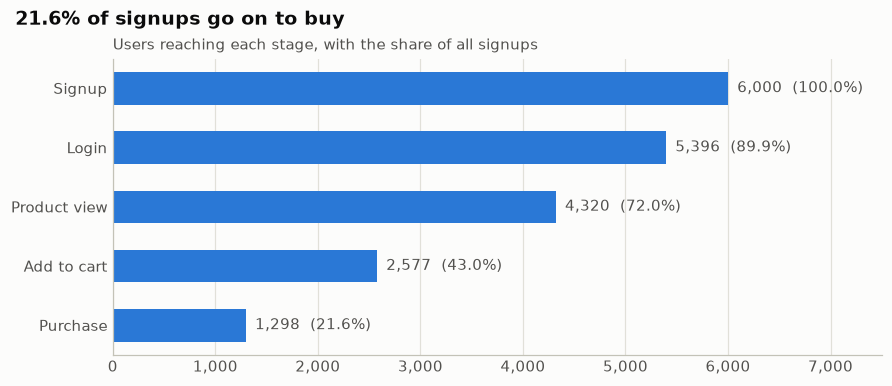

In [6]:
labels = [funnel.STAGE_LABELS[stage] for stage in funnel.STAGES]
users_at_stage = funnel_table["users"].to_numpy()
shares = [funnel.pct(n, users_at_stage[0], places=1) for n in users_at_stage]
y = np.arange(len(labels))[::-1]

fig, ax = plt.subplots(figsize=(8, 3.4), layout="constrained")
ax.barh(y, users_at_stage, height=0.55, color=BLUE)
for position, count, share in zip(y, users_at_stage, shares):
    ax.text(count + users_at_stage[0] * 0.015, position, f"{count:,}  ({share:.1f}%)",
            va="center", color=INK_2)
ax.set_yticks(y, labels)
ax.set_xlim(0, users_at_stage[0] * 1.25)
ax.xaxis.set_major_formatter(thousands)
style_axes(ax, "x")
ax.set_title("Users reaching each stage, with the share of all signups", loc="left")
headline(fig, f"{shares[-1]:.1f}% of signups go on to buy")
save(fig, "funnel.png")
plt.show()

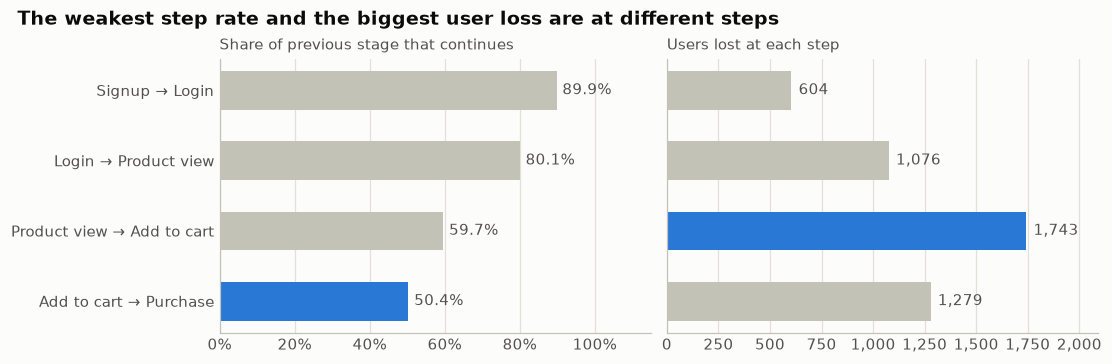

In [7]:
steps = funnel_table.iloc[1:].astype({"previous_stage_users": int, "users_lost": int})
steps["transition"] = [
    f"{funnel.STAGE_LABELS[a]} → {funnel.STAGE_LABELS[b]}"
    for a, b in zip(funnel.STAGES, funnel.STAGES[1:])
]
weakest = steps.loc[steps["step_conversion_pct"].idxmin()]
biggest_loss = steps.loc[steps["users_lost"].idxmax()]
# The prose in this section, section 7 and the README names these two steps.
assert weakest["transition"] == "Add to cart → Purchase", "update the prose: the weakest step changed"
assert biggest_loss["transition"] == "Product view → Add to cart", "update the prose: the biggest loss moved"
rates_1dp = [funnel.pct(n, prev, places=1) for n, prev in zip(steps["users"], steps["previous_stage_users"])]
weakest_rate = funnel.pct(int(weakest["users"]), int(weakest["previous_stage_users"]), places=1)

y = np.arange(len(steps))[::-1]
fig, (rate_ax, lost_ax) = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True, layout="constrained")

rate_colors = [BLUE if t == weakest["transition"] else GREY for t in steps["transition"]]
rate_ax.barh(y, steps["step_conversion_pct"], height=0.55, color=rate_colors)
for position, value in zip(y, rates_1dp):
    rate_ax.text(value + 1.5, position, f"{value:.1f}%", va="center", color=INK_2)
rate_ax.set_xlim(0, 115)
rate_ax.xaxis.set_major_formatter(percent)
rate_ax.set_title("Share of previous stage that continues", loc="left")

lost_colors = [BLUE if t == biggest_loss["transition"] else GREY for t in steps["transition"]]
lost_ax.barh(y, steps["users_lost"], height=0.55, color=lost_colors)
for position, value in zip(y, steps["users_lost"]):
    lost_ax.text(value + steps["users_lost"].max() * 0.02, position, f"{value:,}", va="center", color=INK_2)
lost_ax.set_xlim(0, steps["users_lost"].max() * 1.2)
lost_ax.xaxis.set_major_formatter(thousands)
lost_ax.set_title("Users lost at each step", loc="left")

rate_ax.set_yticks(y, steps["transition"])
for ax in (rate_ax, lost_ax):
    style_axes(ax, "x")
headline(fig, "The weakest step rate and the biggest user loss are at different steps")
save(fig, "step_dropoff.png")
plt.show()

Two different questions give two different answers:

- **Lowest step rate: add to cart → purchase.** About half of the users who add something to the cart never buy.
- **Most users lost: product view → add to cart.** More users reach this step, so a lower drop-off rate still loses more people in absolute terms.

To compare the two levers on one scale, the next cell asks: if one step's conversion improved by one percentage point and every other step stayed the same, how many extra purchases would that produce?

In [8]:
step_rates = steps["step_conversion_pct"].to_numpy() / 100
entering = steps["previous_stage_users"].to_numpy()
downstream = [np.prod(step_rates[i + 1:]) for i in range(len(step_rates))]

sensitivity = pd.DataFrame(
    {
        "transition": steps["transition"].to_numpy(),
        "users entering step": entering,
        "extra purchases per +1 pp": [
            round(n * 0.01 * rest, 1) for n, rest in zip(entering, downstream)
        ],
    }
).sort_values("extra purchases per +1 pp", ascending=False, ignore_index=True)
display(sensitivity)
best_lever = sensitivity.iloc[0]

,transition,users entering step,extra purchases per +1 pp
0,Add to cart → Purchase,2577,25.8
1,Product view → Add to cart,4320,21.8
2,Login → Product view,5396,16.2
3,Signup → Login,6000,14.4


This is not a second, independent finding. Algebraically, the gain from one extra point at a step is 1% of all purchases divided by that step's own rate (here 12.98 / 0.504 ≈ 25.8), so on this scale the step with the lowest rate always comes out on top, wherever it sits in the funnel. Measured as a relative lift instead, every step is worth the same: +1% at any one step gives +1% purchases. The table is still useful for sizing: it says what a one-point gain is worth at each step, which can be weighed against how hard that point would be to win.

## 3. Time to first purchase

Days from signup to first purchase, for users who bought. This describes buyers only. It is not a conversion rate, because users who signed up near the end of the data have had less time to buy.

In [9]:
first_purchases = funnel.first_purchase_after_signup(users, events)
days_table = funnel.days_to_purchase(first_purchases)
display(days_table)
median_days = float(first_purchases["days_to_purchase"].median())
max_days = int(first_purchases["days_to_purchase"].max())
# Section 4's seven-day measure relies on every first purchase falling inside the window.
assert max_days < funnel.FOLLOW_UP_DAYS, "some first purchases fall outside the window; revise sections 3-4"

cart_lag = (dates["purchase"] - dates["add_to_cart"]).dt.days.dropna().astype(int).value_counts().sort_index()
display(cart_lag.rename("buyers").rename_axis("days from add to cart to purchase").to_frame())

,days_to_purchase,observed_purchasers,pct_of_observed_purchasers,cumulative_pct
0,0,37,2.85,2.85
1,1,145,11.17,14.02
2,2,283,21.80,35.82
3,3,350,26.96,62.79
4,4,299,23.04,85.82
5,5,150,11.56,97.38
6,6,34,2.62,100.00


,buyers
days from add to cart to purchase,
0,655
1,643


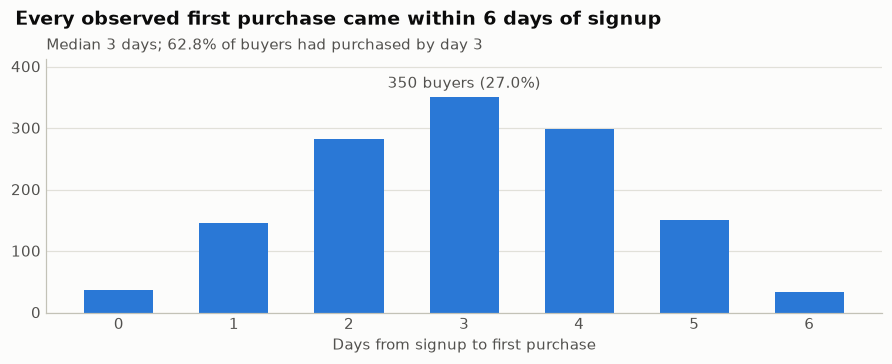

In [10]:
peak = days_table.loc[days_table["observed_purchasers"].idxmax()]
within_median = days_table.loc[days_table["days_to_purchase"] <= median_days, "pct_of_observed_purchasers"].sum()

fig, ax = plt.subplots(figsize=(8, 3.2), layout="constrained")
ax.bar(days_table["days_to_purchase"], days_table["observed_purchasers"], width=0.6, color=BLUE)
ax.annotate(f"{int(peak['observed_purchasers']):,} buyers ({peak['pct_of_observed_purchasers']:.1f}%)",
            (peak["days_to_purchase"], peak["observed_purchasers"]), xytext=(0, 4),
            textcoords="offset points", ha="center", va="bottom", color=INK_2)
ax.set_xticks(days_table["days_to_purchase"])
ax.set_xlabel("Days from signup to first purchase")
ax.set_ylim(0, peak["observed_purchasers"] * 1.18)
ax.yaxis.set_major_formatter(thousands)
style_axes(ax, "y")
ax.set_title(
    f"Median {median_days:g} days; {within_median:.1f}% of buyers had purchased by day {int(median_days)}",
    loc="left",
)
headline(fig, f"Every observed first purchase came within {max_days} days of signup")
save(fig, "days_to_purchase.png")
plt.show()

In this sample every first purchase came within a week of signup, so a seven-day window captures every observed conversion (section 4 relies on this). Treat the 0-6 day spread as a property of the sample rather than of buyer psychology: it follows from each step happening 0-2 days after the previous one (section 1).

For a cart reminder, the clock that matters is time since add to cart, not since signup. Every buyer purchased on the day they added to cart or the next day, and nobody bought later, so a reminder would need to go out within a day of the cart add.

## 4. Seven-day conversion with a complete observation window

The overall rate above includes users who signed up in the last week of the data and had less time to buy. This measure keeps only users with a full seven days of follow-up.

In [11]:
seven_day = funnel.seven_day_conversion(users, events)
display(seven_day)

,signup_cutoff,observed_through,follow_up_days,eligible_users,purchasers_within_7_days,conversion_rate_pct
0,2023-06-26,2023-07-03,7,5896,1270,21.54


The seven-day rate is almost the same as the overall rate, which fits the previous section: purchases that happen at all happen within a week.

## 5. Signup-month cohorts

Does seven-day conversion change depending on when users signed up? Only users with a complete window are included, so the last cohort is not penalised.

In [12]:
eligible, cutoff, observed_through = funnel.mature_users(users, events)
eligible["signup_month"] = eligible["signup_date"].dt.to_period("M")

cohorts = (
    eligible.groupby("signup_month")["converted"]
    .agg(users="size", converted="sum")
    .reset_index()
)
cohorts["conversion_pct"] = [funnel.pct(c, n) for c, n in zip(cohorts["converted"], cohorts["users"])]
cohorts[["ci_low", "ci_high"]] = [wilson_ci(c, n) for c, n in zip(cohorts["converted"], cohorts["users"])]
cohort_test = chi2_contingency(pd.crosstab(eligible["signup_month"], eligible["converted"]))
display(cohorts.round({"ci_low": 2, "ci_high": 2}))
print(f"Chi-square test across months: chi2 = {cohort_test.statistic:.2f}, "
      f"dof = {cohort_test.dof}, {fmt_p(cohort_test.pvalue)}")
print(f"Monthly seven-day conversion ranges from {cohorts['conversion_pct'].min():.1f}% "
      f"to {cohorts['conversion_pct'].max():.1f}%")
assert cohort_test.pvalue >= ALPHA, "months now differ significantly: update the chart headline and prose"

,signup_month,users,converted,conversion_pct,ci_low,ci_high
0,2023-01,1007,205,20.36,17.99,22.95
1,2023-02,921,210,22.80,20.21,25.62
2,2023-03,994,210,21.13,18.70,23.77
3,2023-04,1014,211,20.81,18.42,23.42
4,2023-05,1068,221,20.69,18.37,23.23
5,2023-06,892,213,23.88,21.20,26.79


Chi-square test across months: chi2 = 5.46, dof = 5, p = 0.36
Monthly seven-day conversion ranges from 20.4% to 23.9%


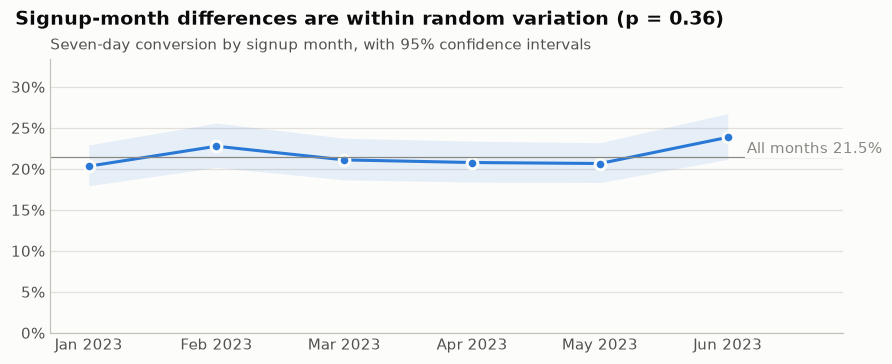

In [13]:
x = np.arange(len(cohorts))
overall_seven_day = seven_day["conversion_rate_pct"].item()

fig, ax = plt.subplots(figsize=(8, 3.2), layout="constrained")
ax.fill_between(x, cohorts["ci_low"], cohorts["ci_high"], color=BLUE, alpha=0.1, linewidth=0)
ax.plot(x, cohorts["conversion_pct"], color=BLUE, linewidth=2, marker="o", markersize=7,
        markeredgecolor=SURFACE, markeredgewidth=2, solid_capstyle="round")
ax.axhline(overall_seven_day, color=MUTED, linewidth=0.8)
ax.text(x[-1] + 0.15, overall_seven_day, f"All months {overall_seven_day:.1f}%", va="bottom", color=MUTED,
        bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1))
ax.set_xticks(x, [period.strftime("%b %Y") for period in cohorts["signup_month"]])
ax.set_xlim(-0.3, x[-1] + 0.9)
ax.set_ylim(0, max(cohorts["ci_high"]) * 1.25)
ax.yaxis.set_major_formatter(percent)
style_axes(ax, "y")
ax.set_title("Seven-day conversion by signup month, with 95% confidence intervals", loc="left")
headline(fig, f"Signup-month differences are within random variation ({fmt_p(cohort_test.pvalue)})")
save(fig, "cohort_conversion.png")
plt.show()

The monthly rates differ by a few points (range printed above), but every confidence interval overlaps the overall rate and the chi-square test finds no significant difference between months. That is not proof the months are identical; the next section shows how large a gap tests of this size can detect.

## 6. Country comparison

Signup-to-purchase conversion by country, then the same test at each funnel step among users who reached the previous stage.

In [14]:
countries = funnel.country_conversion(users, first_purchases)
countries[["ci_low", "ci_high"]] = [
    wilson_ci(p, n) for p, n in zip(countries["valid_purchases"], countries["total_users"])
]
purchased = users["user_id"].isin(first_purchases.index)
country_test = chi2_contingency(pd.crosstab(users["country"], purchased))
display(countries.round({"ci_low": 2, "ci_high": 2}))
print(f"Chi-square test across countries: chi2 = {country_test.statistic:.2f}, "
      f"dof = {country_test.dof}, {fmt_p(country_test.pvalue)}")
assert country_test.pvalue >= ALPHA, "countries now differ significantly: update the chart headline and prose"

,country,total_users,valid_purchases,conversion_rate_pct,ci_low,ci_high
0,Germany,1003,227,22.63,20.15,25.32
1,India,1048,232,22.14,19.73,24.75
2,Australia,956,208,21.76,19.26,24.48
3,Canada,949,205,21.60,19.10,24.33
4,USA,1079,228,21.13,18.80,23.67
5,UK,965,198,20.52,18.09,23.18


Chi-square test across countries: chi2 = 1.63, dof = 5, p = 0.90


In [15]:
country_by_user = users.set_index("user_id")["country"].reindex(dates.index)
step_tests = []
for previous, stage in zip(funnel.STAGES, funnel.STAGES[1:]):
    reached_previous = dates[previous].notna()
    table = pd.crosstab(country_by_user[reached_previous], dates.loc[reached_previous, stage].notna())
    rates = table[True] / table.sum(axis=1) * 100
    step_tests.append(
        {
            "transition": f"{funnel.STAGE_LABELS[previous]} → {funnel.STAGE_LABELS[stage]}",
            "lowest country": f"{rates.idxmin()} ({rates.min():.1f}%)",
            "highest country": f"{rates.idxmax()} ({rates.max():.1f}%)",
            "p_value": round(chi2_contingency(table).pvalue, 3),
        }
    )
step_tests = pd.DataFrame(step_tests)
display(step_tests)
assert step_tests["p_value"].min() >= ALPHA, "a step now differs by country: update the prose"


def detectable_gap(rate, users_per_group):
    # Smallest gap between two groups found 80% of the time at alpha 0.05, in percentage points.
    return 100 * (1.96 + 0.84) * np.sqrt(2 * rate * (1 - rate) / users_per_group)


per_country = len(users) / users["country"].nunique()
cart_users = dates["add_to_cart"].notna()
cart_rate = dates.loc[cart_users, "purchase"].notna().mean()
cart_per_country = cart_users.sum() / users["country"].nunique()
print(f"About {per_country:,.0f} users per country: overall conversion gaps of about "
      f"{detectable_gap(purchased.mean(), per_country):.1f} points are reliably detectable.")
print(f"About {cart_per_country:,.0f} cart users per country: add to cart -> purchase gaps of about "
      f"{detectable_gap(cart_rate, cart_per_country):.1f} points are reliably detectable.")

,transition,lowest country,highest country,p_value
0,Signup → Login,Canada (88.5%),Germany (90.8%),0.555
1,Login → Product view,India (79.0%),Australia (81.1%),0.822
2,Product view → Add to cart,Germany (56.4%),Australia (61.6%),0.389
3,Add to cart → Purchase,UK (47.5%),Germany (55.4%),0.201


About 1,000 users per country: overall conversion gaps of about 5.2 points are reliably detectable.
About 430 cart users per country: add to cart -> purchase gaps of about 9.6 points are reliably detectable.


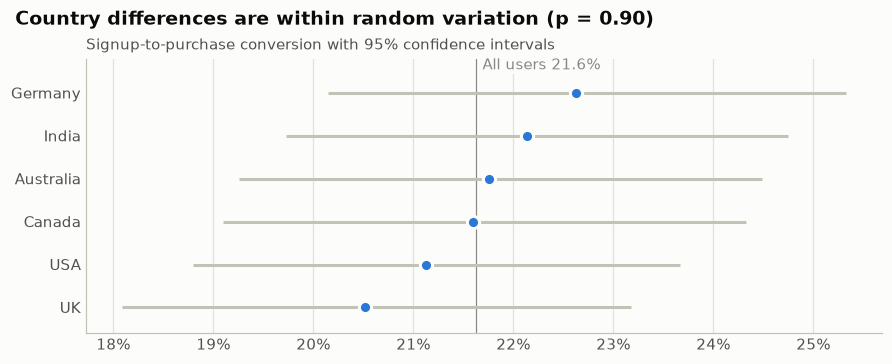

In [16]:
ordered = countries.sort_values("conversion_rate_pct", ignore_index=True)
y = np.arange(len(ordered))
overall_rate = funnel_table["cumulative_conversion_pct"].iloc[-1]

fig, ax = plt.subplots(figsize=(8, 3.2), layout="constrained")
ax.axvline(overall_rate, color=MUTED, linewidth=0.8)
ax.hlines(y, ordered["ci_low"], ordered["ci_high"], color=GREY, linewidth=2)
ax.plot(ordered["conversion_rate_pct"], y, "o", color=BLUE, markersize=8,
        markeredgecolor=SURFACE, markeredgewidth=2)
ax.annotate(f"All users {overall_rate:.1f}%", (overall_rate, len(ordered) - 0.45), xytext=(4, 0),
            textcoords="offset points", ha="left", color=MUTED,
            bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1))
ax.set_yticks(y, ordered["country"])
ax.set_ylim(-0.6, len(ordered) - 0.2)
ax.xaxis.set_major_formatter(percent)
style_axes(ax, "x")
ax.set_title("Signup-to-purchase conversion with 95% confidence intervals", loc="left")
headline(fig, f"Country differences are within random variation ({fmt_p(country_test.pvalue)})")
save(fig, "country_conversion.png")
plt.show()

The gap between the highest and lowest country is about two percentage points, and every confidence interval overlaps the overall rate. No funnel step shows a significant country difference either (the smallest of the four step tests has p = 0.20).

That is not proof the countries behave identically. With about 1,000 users per country, tests like these reliably detect only gaps of roughly 5 points in overall conversion, and roughly 10 points at the cart step (printed above), so smaller real differences cannot be ruled out. On this data there is simply no evidence that country matters.

## 7. Summary, recommendations and limitations

In [17]:
signups = int(funnel_table["users"].iloc[0])
purchases = int(funnel_table["users"].iloc[-1])
display(Markdown(f'''
**Key findings**

1. **{purchases:,} of {signups:,} signups ({shares[-1]:.1f}%) made a purchase.**
2. **The weakest step is {weakest["transition"].lower()}** ({weakest_rate:.1f}% continue):
   one extra percentage point there is worth about {best_lever["extra purchases per +1 pp"]:.0f} purchases per {signups:,} signups.
3. **The most users are lost at {biggest_loss["transition"].lower()}** ({int(biggest_loss["users_lost"]):,} users).
4. **Every buyer purchased within a day of adding to cart**, and every first purchase came within {max_days} days of signup
   (median {median_days:g}). Both follow from how tightly the steps are spaced in this sample.
   Seven-day conversion among users with a full window is {overall_seven_day:.2f}%.
5. **No segment stands out**: neither countries ({fmt_p(country_test.pvalue)}) nor signup months
   ({fmt_p(cohort_test.pvalue)}) differ significantly.
'''))


**Key findings**

1. **1,298 of 6,000 signups (21.6%) made a purchase.**
2. **The weakest step is add to cart → purchase** (50.4% continue):
   one extra percentage point there is worth about 26 purchases per 6,000 signups.
3. **The most users are lost at product view → add to cart** (1,743 users).
4. **Every buyer purchased within a day of adding to cart**, and every first purchase came within 6 days of signup
   (median 3). Both follow from how tightly the steps are spaced in this sample.
   Seven-day conversion among users with a full window is 21.54%.
5. **No segment stands out**: neither countries (p = 0.90) nor signup months
   (p = 0.36) differ significantly.


**Recommendations** (hypotheses to test with controlled experiments, since this data cannot show cause and effect)

- **Start after add to cart ("checkout" for short).** Add to cart → purchase has the lowest step rate, so a point gained there is worth the most purchases. The data has no checkout-start event, so it cannot separate cart abandonment from checkout abandonment; candidate tests cover both: show the total cost earlier, offer guest checkout, and send a cart reminder within a day of the cart add (every buyer here bought the same day or the next).
- **Then product pages.** Product view → add to cart loses the most users. Candidate tests: clearer pricing and availability, reviews, and stronger calls to action.
- **Do not split the work by country yet.** No country differs significantly, so one funnel-wide experiment has more statistical power than six country-specific ones.
- **Improve the tracking.** Event timestamps, a checkout-start event, session IDs, order values and product IDs would allow session-level funnels, revenue impact and product-level analysis.

**Limitations**

- The sample looks simulated (section 1) and its source was not recorded, so the results illustrate the method rather than describe a real business.
- Events are dated, not timestamped, so same-day stage order is assumed.
- There is no revenue, order, session or product data.
- Segment comparisons are descriptive. The chi-square tests show whether differences exceed random variation, not why they occur.

## 8. Export

These are the tables the MySQL queries must reproduce. `scripts/validate_results.py` compares them with the query output, and CI fails if the committed CSVs are out of date.

In [18]:
for name, table in funnel.sql_result_tables(users, events).items():
    (OUTPUTS / name).write_text(funnel.to_csv_text(table), encoding="utf-8", newline="\n")
    print(f"wrote outputs/{name}")
print("figures:", ", ".join(sorted(path.name for path in FIGURES.glob("*.png"))))

wrote outputs/02_funnel_metrics.csv
wrote outputs/03_days_to_purchase.csv
wrote outputs/04_country_segmentation.csv
wrote outputs/05_seven_day_conversion.csv
figures: cohort_conversion.png, country_conversion.png, days_to_purchase.png, funnel.png, step_dropoff.png
